In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN         #modelos no supervisados
from sklearn.metrics import silhouette_score        #indice de silueta
from sklearn.decomposition import PCA               #Reducción de dimensionalidad
from sklearn.manifold import TSNE                   #Reducción de dimensionalidad
from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings('ignore')

Importación de datos

In [3]:
#Data sin escalar
X_no_escalado = pd.read_csv('../data/processed/X_No escalado.csv', index_col=0, encoding='utf-8')
y = pd.read_csv('../data/processed/y.csv', index_col=0, encoding='utf-8')

#Escalado de X
scaler = StandardScaler()
X_Scaled = pd.DataFrame(scaler.fit_transform(X_no_escalado), columns=X_no_escalado.columns, index=X_no_escalado.index)

print(f'Matriz de variables (X) cargada con éxito. Forma: {X_Scaled.shape}')
print(f'"Exited" (y). Forma: {y.shape}\n')
print(f'Features finales: {X_Scaled.columns}')

display(X_Scaled.head(3))

Matriz de variables (X) cargada con éxito. Forma: (10000, 11)
"Exited" (y). Forma: (10000, 1)

Features finales: Index(['CreditScore', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts',
       'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany',
       'Geography_Spain'],
      dtype='str')


,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain
0,-0.326221,-1.095988,0.293517,-1.041760,-1.225848,-0.911583,0.646092,0.970243,0.021886,-0.578736,-0.573809
1,-0.440036,-1.095988,0.198164,-1.387538,0.117350,-0.911583,-1.547768,0.970243,0.216534,-0.578736,1.742740
2,-1.536794,-1.095988,0.293517,1.032908,1.333053,2.527057,0.646092,-1.030670,0.240687,-0.578736,-0.573809


Modelos

KMEANS

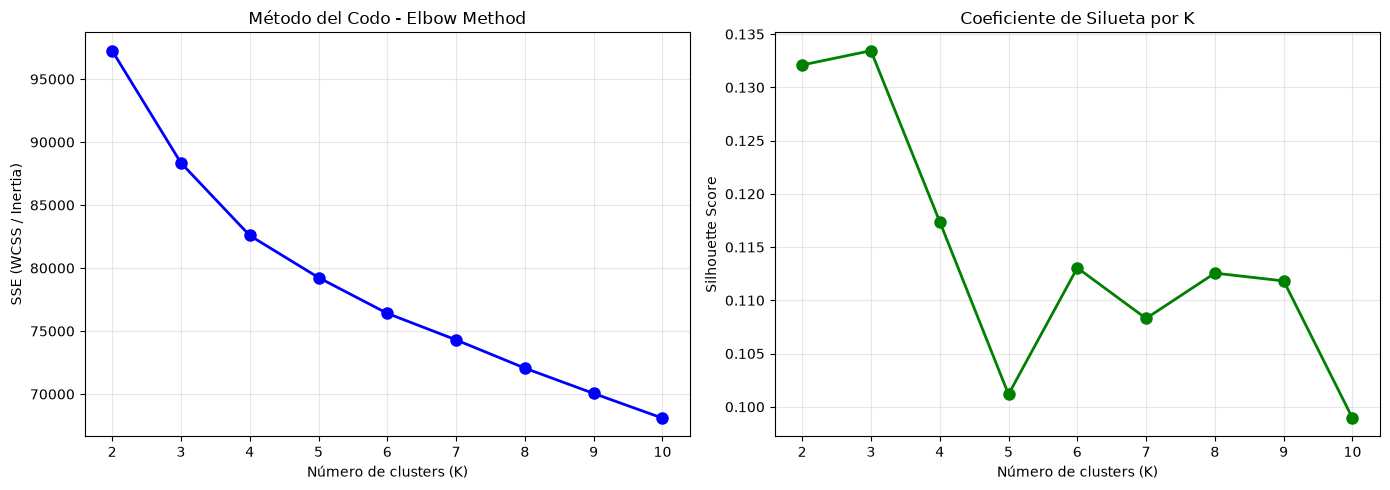

In [4]:
#K-Means clustering
k_range = range(2,11)
sse_list = []
silhouette_list = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init= 10)
    km = km.fit(X_Scaled)
    sse_list.append(km.inertia_)
    silhouette_list.append(silhouette_score(X_Scaled,km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_range, sse_list, 'bo-', linewidth=2, markersize=8)
axes[0].set_xlabel('Número de clusters (K)')
axes[0].set_ylabel('SSE (WCSS / Inertia)')
axes[0].set_title('Método del Codo - Elbow Method')
axes[0].set_xticks(k_range)
axes[0].grid(True, alpha=0.3)

axes[1].plot(k_range, silhouette_list, 'go-', linewidth=2, markersize=8)
axes[1].set_xlabel('Número de clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Coeficiente de Silueta por K')
axes[1].set_xticks(k_range)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#Silueta
#0.5> Alta cohesion interna y alta separación con el cluster más cercano
#[0.25-0.5] Razonable
#<0.25 Débil/solapada, no es una división natural


Observando la gráfica del codo, se nota un descenso suave en la inercia (SSE) al aumentar el número de clusters pero sin mostrar un punto de inflexión marcado. Por otro lado, el punto más óptimo en el gráfico de silueta es de 0.134 aproximadamente, señalando un k=3. Sin embargo, este valor nos indica que los grupos se solapan entre sí, por lo que se puede concluir que no hay una división marcada para los grupos.

In [5]:
#Se entrena con k=3
km_optimal = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_Scaled)

print(f'Resultados reales para la opción elegida:')
print(f'K = 3 clusters')
print(f'Silhouette Score = {silhouette_list[1]:.4f}')
print(f'Tamaños de cada cluster = {np.bincount(km_optimal.labels_)}')

Resultados reales para la opción elegida:
K = 3 clusters
Silhouette Score = 0.1334
Tamaños de cada cluster = [2509 5014 2477]


In [6]:
#centroides
centroids_scaled = km_optimal.cluster_centers_

# Creamos el DataFrame usando el nombre exacto de tus columnas
centroids_df = pd.DataFrame(centroids_scaled, columns=X_Scaled.columns)
centroids_df.insert(0, 'Cluster', range(3))

# 2. Volver a escala original para interpretación
centroids_original = scaler.inverse_transform(centroids_scaled)

# Creamos el DataFrame final mapeando tus columnas originales
centroids_orig_df = pd.DataFrame(centroids_original, columns=X_no_escalado.columns)
centroids_orig_df.insert(0, 'Cluster', range(3))


print("Centroides en escala original:")
display(centroids_orig_df.round(2).T)


Centroides en escala original:


,0,1,2
Cluster,0.00,1.00,2.00
CreditScore,651.45,649.67,651.33
Gender,0.52,0.55,0.56
Age,39.77,38.51,38.89
Tenure,5.01,5.00,5.03
Balance,119730.12,62092.64,61818.15
NumOfProducts,1.52,1.53,1.54
HasCrCard,0.71,0.71,0.69
IsActiveMember,0.50,0.52,0.53
EstimatedSalary,101113.44,99899.18,99440.57


Con los centroides se corrobora lo concluido de la gráfica del codo y de silueta, al ser los centroides cercanos entre sí, no hay una distinción marcada entre ellas, salvo por geografía que clasifica en 3 grupos (Alemania, Francia, España) y el balance que divide por 119,730.12, 62,092.64 y 61,818.15. Siendo los dos últimos un poco más cercanos

DBSCAN

In [7]:
#DBSCAN (Density-Based clustering):
db = DBSCAN(eps=0.5, min_samples=5)
db.fit(X_Scaled)
labels_db = db.labels_
n_clusters_db = len(set(labels_db)) - (1 if -1 in labels_db else 0)   #etiquetas de cluster
n_noise = (labels_db == -1).sum()    #outliers

print('Resultados DBSCAN')
print(f'Clusters encontrados: {n_clusters_db}')
print(f'Outliers (ruido, label=-1): {n_noise} ({n_noise/len(labels_db)*100:.1f}%)')
print(f'Distribución por cluster: {np.bincount(labels_db[labels_db >= 0]) if n_clusters_db > 0 else "N/A"}')

df_resultados_dbscan = X_no_escalado.copy()
df_resultados_dbscan['cluster_dbscan'] = labels_db


Resultados DBSCAN
Clusters encontrados: 14
Outliers (ruido, label=-1): 9921 (99.2%)
Distribución por cluster: [7 7 5 5 7 7 6 5 5 5 5 5 5 5]


El algoritmo DBSCAN corrobora lo concluído en Kmeans. Con un radio de búsqueda eps=0.5, el 99.2% de las observaciones (9921 registros) fueron clasificadas como ruido (outliers, etiqueta -1), lo que evidencia una severa falta de densidad aislada en el espacio multidimensional.
Si se realiza el aumento de este radio a 0.6, contrariamente aumenta el número de grupos a 48, lo que indica que hay muchos más datos solapados dificiles de segmentar, como una nube grande de puntos homogéneos. Para efectos prácticos se tomará la solución de kMeans para poder implementar estrategias de negocio.

Reducción de dimensionalidad

PCA (Principal Component Analysis)

Componentes para 80% varianza: 8
Componentes para 90% varianza: 10
Varianza acumulada (2 componentes): 25.37%
🔹 Variables dominantes en PC1:
   - Geography_Germany: 0.598
   - Balance: 0.598
   - Geography_Spain: -0.433
--------------------------------------------------
🔹 Variables dominantes en PC2:
   - NumOfProducts: 0.627
   - Geography_Spain: -0.435
   - IsActiveMember: -0.300
--------------------------------------------------
🔹 Variables dominantes en PC3:
   - IsActiveMember: 0.584
   - Age: 0.553
   - NumOfProducts: 0.338
--------------------------------------------------
🔹 Variables dominantes en PC4:
   - HasCrCard: 0.556
   - Gender: 0.505
   - Tenure: 0.401
--------------------------------------------------
🔹 Variables dominantes en PC5:
   - CreditScore: 0.729
   - EstimatedSalary: 0.374
   - HasCrCard: -0.349
--------------------------------------------------
🔹 Variables dominantes en PC6:
   - EstimatedSalary: 0.678
   - Tenure: 0.577
   - Age: 0.356
--------------------

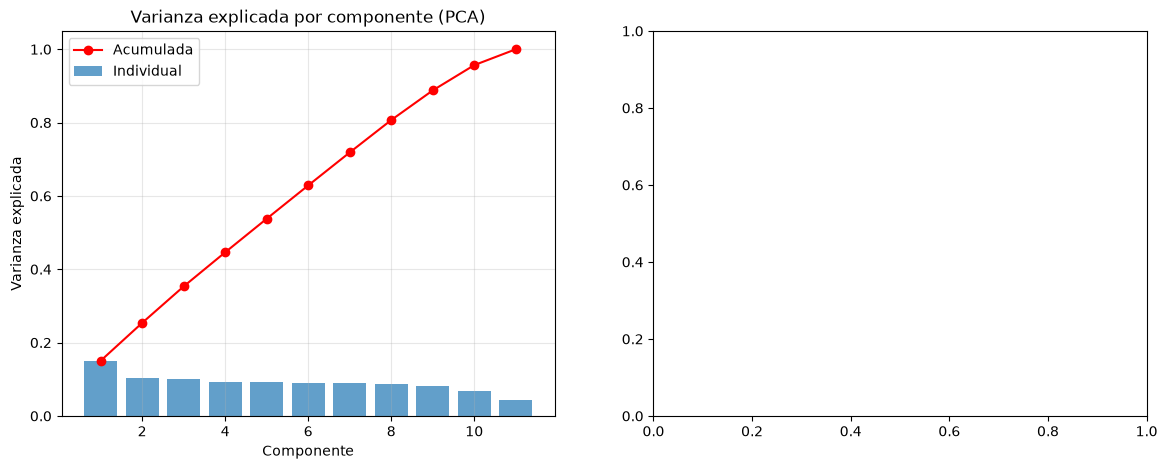

In [8]:
#PCA (Principal Component Analysis):
pca_full = PCA(random_state=42)
pca_full.fit(X_Scaled)

# Varianza explicada por componente
var_exp = pca_full.explained_variance_ratio_
var_exp_cum = np.cumsum(var_exp)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(range(1, len(var_exp)+1), var_exp, alpha=0.7, label='Individual')
axes[0].plot(range(1, len(var_exp)+1), var_exp_cum, 'ro-', label='Acumulada')
axes[0].set_xlabel('Componente')
axes[0].set_ylabel('Varianza explicada')
axes[0].set_title('Varianza explicada por componente (PCA)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# N componentes que explican 80-90% varianza
n_90 = np.searchsorted(var_exp_cum, 0.90) + 1
n_80 = np.searchsorted(var_exp_cum, 0.80) + 1
print(f"Componentes para 80% varianza: {n_80}")
print(f"Componentes para 90% varianza: {n_90}")
print(f"Varianza acumulada (2 componentes): {var_exp_cum[1]:.2%}")
for i in range(len(X_Scaled.columns)):
    #DataFrame con los pesos de este componente específico
    df_componente = pd.DataFrame(
        pca_full.components_[i], 
        index=X_Scaled.columns, 
        columns=['Peso']
    )
    
    # Orden por el valor absoluto del peso (de mayor a menor impacto)
    top_variables = df_componente.abs().sort_values(by='Peso', ascending=False).head(3)
    
    # Imprimimos el resultado con formato limpio
    print(f"🔹 Variables dominantes en PC{i+1}:")
    for var, row in top_variables.iterrows():
        # Recuperamos el signo original para saber si es relación positiva o negativa
        peso_real = df_componente.loc[var, 'Peso']
        print(f"   - {var}: {peso_real:.3f}")
    print("-" * 50)

PCA no funciona muy bien para este caso ya que las variable predictoras tienen muy baja o no existen multicolinealidad entre ellas, por eso se explica apenas el 25 % de la variabilidad con los dos primeros componentes.

Varianza explicada PC1 y PC2: [0.15042958 0.10330298]
Total 2 componentes: 0.25373256322770366


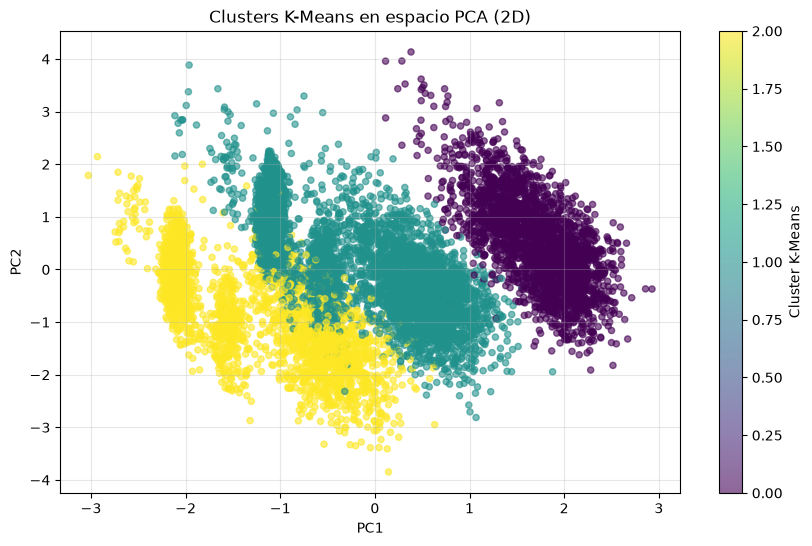

In [9]:
pca_2d = PCA(n_components=2, random_state=42)
X_pca = pca_2d.fit_transform(X_Scaled)

print('Varianza explicada PC1 y PC2:', pca_2d.explained_variance_ratio_)
print('Total 2 componentes:', sum(pca_2d.explained_variance_ratio_))

# Visualizar clusters K-Means en espacio PCA
plt.figure(figsize=(10, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=km_optimal.labels_, cmap='viridis', alpha=0.6, s=20)

plt.colorbar(scatter, label='Cluster K-Means')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Clusters K-Means en espacio PCA (2D)')
plt.grid(True, alpha=0.3)
plt.show()

Grupo Morado (Alemania): Se separa por completo hacia la derecha debido a sus altos balances de cuenta. 
Grupos Verde (Francia) y Amarillo (España): Aparecen mezclados en el centro porque comparten características idénticas de edad, salario y productos. La gráfica confirma visualmente el bajo índice de silueta. Los datos se solapan continuamente, excepto por el grupo de Alemania que se segmenta con claridad.

T-SNE

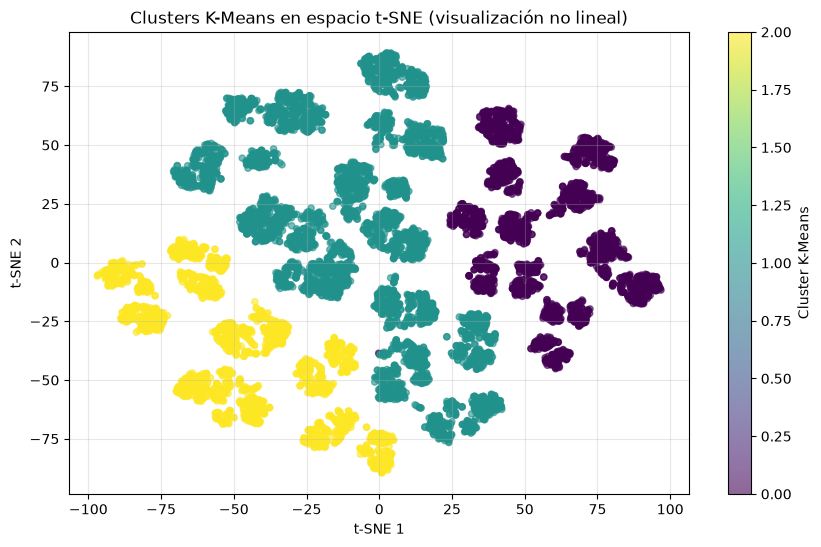

In [10]:
#t-SNE básico
# perplexity típico en la industra 30 (menor=enfocado en vecinos cercanos)
# Nota: t-SNE es costoso; para 10k filas puede tardar 1-2 min
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_Scaled)

# Visualizar con clusters K-Means
plt.figure(figsize=(10, 6))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=km_optimal.labels_, cmap='viridis', alpha=0.6, s=20)
plt.colorbar(scatter, label='Cluster K-Means')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.title('Clusters K-Means en espacio t-SNE (visualización no lineal)')
plt.grid(True, alpha=0.3)
plt.show()

La reduccion de dimensionalidad nos muestra que las 11 variables tienen una relación no lineal que no podría ser capturada con PCA. Se observa que existen agrupamiento de pequeñas islas de forma local para cada país. Esto además, soporta los resultados que se obtuvieron con DBSCAN al aumentar el radio de búsqueda epsilon. Para una búsqueda de media desviación estándar encontraba 14 grupos, pero al aumentar el radio aparecían 48.


Segmentación

In [11]:
df_model = X_no_escalado.copy()
df_model['cluster_kmeans'] = km_optimal.labels_
df_model['Exited'] = y.values

profile_vars = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
profiles = df_model.groupby('cluster_kmeans')[profile_vars].mean().round(2)
profiles['Churn_Rate_%'] = (df_model.groupby('cluster_kmeans')['Exited'].mean() * 100).round(1)
profiles['Count'] = df_model.groupby('cluster_kmeans').size()

# Geografía y Género en %
geo_agg = df_model.groupby('cluster_kmeans')[['Geography_Germany', 'Geography_Spain']].mean()
geo_agg.columns = ['% Germany', '% Spain']

# Convertimos a porcentajes para que coincida con Churn_Rate_%
profiles = profiles.join((geo_agg * 100).round(1))
profiles['% Male'] = (df_model.groupby('cluster_kmeans')['Gender'].mean() * 100).round(1)

# 4. Despliegue de la tabla final transpuesta (es mucho más cómoda de leer hacia abajo)
print('Perfiles por Cluster (promedios y proporciones de negocio)')
display(profiles.T)

Perfiles por Cluster (promedios y proporciones de negocio)


cluster_kmeans,0,1,2
CreditScore,651.45,649.67,651.33
Age,39.77,38.51,38.89
Tenure,5.01,5.00,5.03
Balance,119730.12,62092.64,61818.15
NumOfProducts,1.52,1.53,1.54
HasCrCard,0.71,0.71,0.69
IsActiveMember,0.50,0.52,0.53
EstimatedSalary,101113.44,99899.18,99440.57
Churn_Rate_%,32.40,16.20,16.70
Count,2509.00,5014.00,2477.00


In [12]:
#Feature Derivada 1: Distancia euclidiana de cada cliente a su centroide asignado
# km_optimal.transform nos da la distancia a todos los centros; nos quedamos con la mínima
distancias_a_centros = km_optimal.transform(X_Scaled)
df_model['distancia_centroide'] = distancias_a_centros.min(axis=1).round(4)

# Feature Derivada 2: Mapear el nivel de riesgo de deserción según la tasa de churn del cluster
tasas_churn = df_model.groupby('cluster_kmeans')['Exited'].mean()
print('Tasas de Churn por cluster detectadas:')
print(tasas_churn.round(4))

# Diccionario de etiquetas por tasa de churn
#Referencia de los valores obtenidos en Churn_rate% de los perfiles
mapeo_riesgo = {}
for clus, tasa in tasas_churn.items():
    if tasa > 0.25:
        mapeo_riesgo[clus] = 'Alto Riesgo'
    elif tasa > 0.18:
        mapeo_riesgo[clus] = 'Medio Riesgo'
    else:
        mapeo_riesgo[clus] = 'Bajo Riesgo'

df_model['nivel_riesgo_cluster'] = df_model['cluster_kmeans'].map(mapeo_riesgo)

print('Dataframe con las features derivadas')
display(df_model[['cluster_kmeans', 'distancia_centroide', 'nivel_riesgo_cluster', 'Exited']].head(10))

Tasas de Churn por cluster detectadas:
cluster_kmeans
0    0.3244
1    0.1615
2    0.1667
Name: Exited, dtype: float64
Dataframe con las features derivadas


,cluster_kmeans,distancia_centroide,nivel_riesgo_cluster,Exited
0,1,2.3833,Bajo Riesgo,1
1,2,2.7744,Bajo Riesgo,0
2,1,3.8861,Bajo Riesgo,1
3,1,2.9190,Bajo Riesgo,0
4,2,3.1790,Bajo Riesgo,0
5,2,2.3941,Bajo Riesgo,1
6,1,3.3326,Bajo Riesgo,0
7,0,5.4850,Alto Riesgo,1
8,1,3.0660,Bajo Riesgo,0
9,1,2.6465,Bajo Riesgo,0


Segmentación por t_SNE

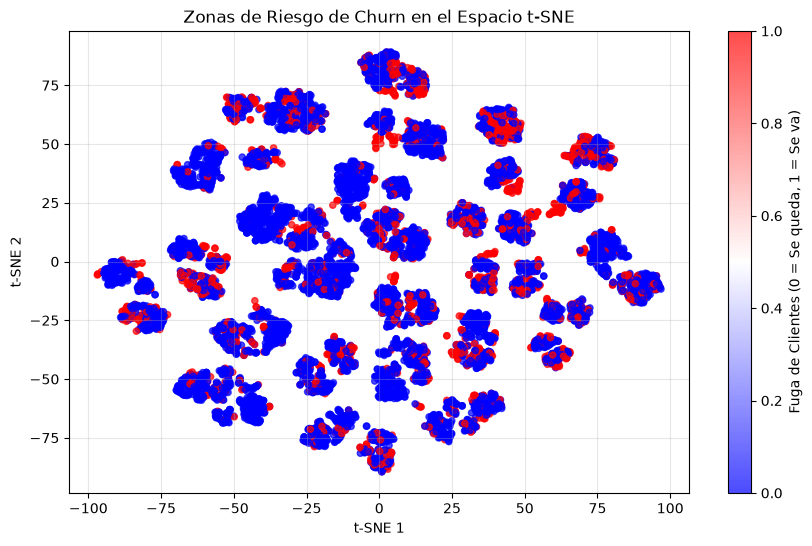

In [13]:
plt.figure(figsize=(10, 6))
# Pintamos el mapa usando la variable real de Churn (y)
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y.iloc[:, 0], cmap='bwr', alpha=0.7, s=20)

plt.colorbar(scatter, label='Fuga de Clientes (0 = Se queda, 1 = Se va)')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.title('Zonas de Riesgo de Churn en el Espacio t-SNE')
plt.grid(True, alpha=0.3)
plt.show()

In [14]:
#Identificación de islas
df_auditoria = X_no_escalado.copy()
#Asignación de coordenadas
df_auditoria['tsne_x'] = X_tsne[:, 0]
df_auditoria['tsne_y'] = X_tsne[:, 1]
df_auditoria['Exited'] = y.values  # Variable de Churn

# 2. Filtramos las coordenadas exactas de la isla roja superior (X entre -10 y 10, Y entre 70 y 90)
isla_critica = df_auditoria[
    (df_auditoria['tsne_x'] >= 25) & (df_auditoria['tsne_x'] <= 50) &
    (df_auditoria['tsne_y'] >= 50) & (df_auditoria['tsne_y'] <= 75)
]

# 3. Calculamos las estadísticas promedio de esa isla específica
print(f'--- CARACTERÍSTICAS DE LA ISLA CRÍTICA SUPERIOR ---')
print(f'Cantidad de clientes en esta isla: {len(isla_critica)}')
print(f'Tasa de Churn real en esta isla: {isla_critica["Exited"].mean():.2%}\n')

print('Perfil promedio de los clientes en esta zona:')
display(isla_critica.mean().round(2))

--- CARACTERÍSTICAS DE LA ISLA CRÍTICA SUPERIOR ---
Cantidad de clientes en esta isla: 277
Tasa de Churn real en esta isla: 53.07%

Perfil promedio de los clientes en esta zona:


CreditScore             653.16
Gender                    0.00
Age                      41.03
Tenure                    5.22
Balance              120729.43
NumOfProducts             1.00
HasCrCard                 1.00
IsActiveMember            0.00
EstimatedSalary      105392.71
Geography_Germany         1.00
Geography_Spain           0.00
tsne_x                   41.54
tsne_y                   58.02
Exited                    0.53
dtype: float64

En este caso se selecciona una de las islas que visualmente tiene mayor concentración de churn que es la ubicada entre las coordenadas para t-SNE1 [25-50] y t-SNE2 [50-75], tiene un porcentaje local de churn del 53% para una isla de 277 clientes. Esto terminaría aportando al churn global en 1.47%